# Линейная регрессия

In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
y = <x, w>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data = pd.read_csv('./data/diamonds.csv')

In [5]:
data.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [6]:
data['price'].describe()

count    53940.000000
mean      3932.799722
std       3989.439738
min        326.000000
25%        950.000000
50%       2401.000000
75%       5324.250000
max      18823.000000
Name: price, dtype: float64

In [7]:
data['color'].value_counts()

color
G    11292
E     9797
F     9542
H     8304
D     6775
I     5422
J     2808
Name: count, dtype: int64

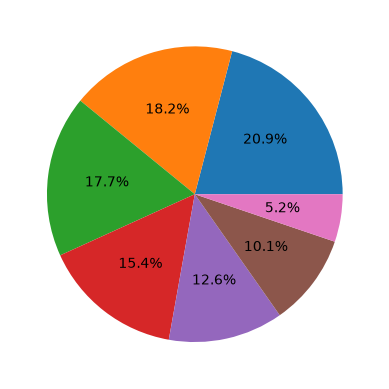

In [8]:
plt.pie(data.color.value_counts(), 
        autopct = '%1.1f%%')

Text(0.5, 1.0, 'Count of cut')

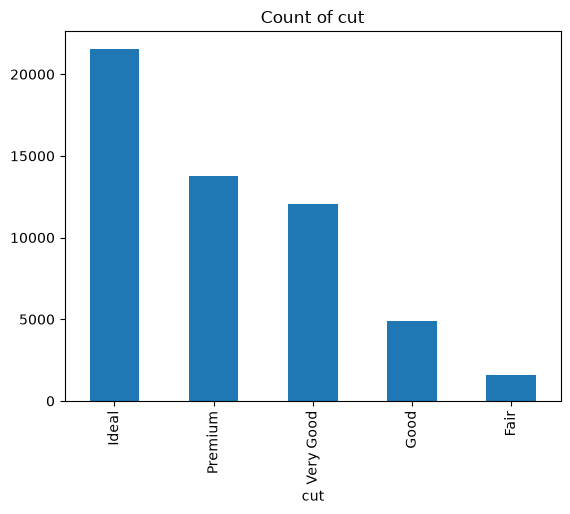

In [9]:
data["cut"].value_counts().plot(kind='bar')
plt.title('Count of cut')

Text(0.5, 1.0, 'Count of clartiy')

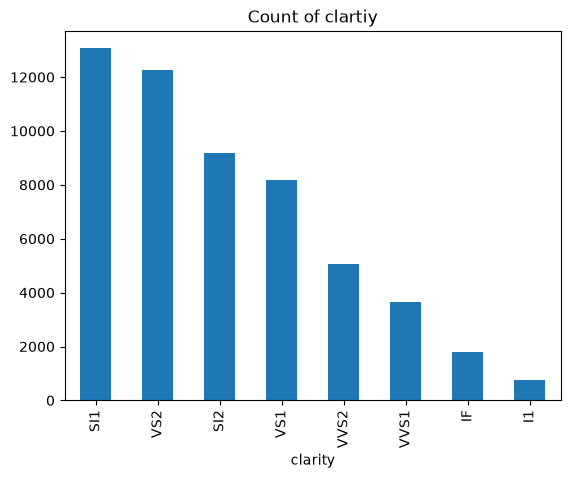

In [10]:
data["clarity"].value_counts().plot(kind='bar')
plt.title('Count of clartiy')

<Axes: >

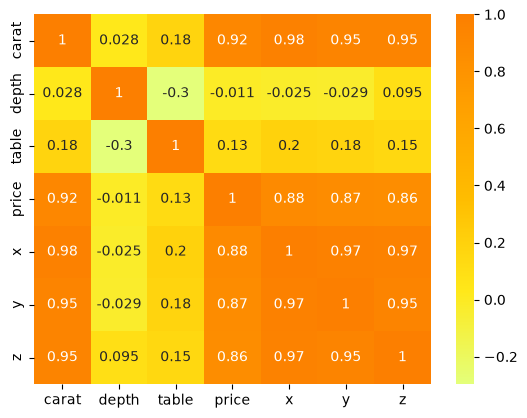

In [11]:
corr_matrix = data.corr(numeric_only=True)
sns.heatmap(corr_matrix, cmap='Wistia', annot=True)

## Предобработка данных

In [12]:
y = data['price']
X = data.drop(columns = "price")

In [13]:
numeric_data = X.select_dtypes(np.number)
numeric_features = numeric_data.columns
numeric_features

Index(['carat', 'depth', 'table', 'x', 'y', 'z'], dtype='str')

In [14]:
categorical_data = X.select_dtypes(object)
categorical_features = categorical_data.columns
categorical_features

/var/folders/80/bqmzx3_x1459py2jpkdyqrz40000gn/T/ipykernel_66295/162981426.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_data = X.select_dtypes(object)


Index(['cut', 'color', 'clarity'], dtype='str')

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [16]:
y_train

26546    16231
9159      4540
14131     5729
15757     6300
24632    12968
         ...  
11284     4975
44732     1617
38158     1014
860       2871
15795     6320
Name: price, Length: 43152, dtype: int64

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.preprocessing import StandardScaler


ct = ColumnTransformer([
    ('ohe', OneHotEncoder(), categorical_features),
    ('scaler', StandardScaler(), numeric_features)
])

In [18]:
X_train = ct.fit_transform(X_train)
X_test = ct.transform(X_test)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import SGDRegressor


model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [23]:
y_pred

array([ 711.88577262, 3191.72583727, 1947.2464112 , ...,  882.50687313,
       8708.75954785, 3060.98990808], shape=(10788,))

In [29]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error as rmse 

# mean_absolute_error(y_test, y_pred)
rmse(y_test, y_pred)

1135.2116445190627

In [23]:
import sys
sys.path.append('linear_model')

## Аналитическое решение

In [24]:
from LinearModelAnalytics import Lin_reg_analytic

analytics = Lin_reg_analytic()
analytics.fit(X_train, y_train)

In [25]:
preds = analytics.predict(X_test)
mean_absolute_error(y_test, preds)

737.1513665933275

## Градиентный спуск

In [26]:
from LinearModel import LinearReg

alt_model = LinearReg()
alt_model.fit(X_train, y_train)

In [27]:
y_pred = model.predict(X_test)
mean_absolute_error(y_test, y_pred)

736.9106820077865

## SGD

In [28]:
from LinearModelSGD import Lin_reg_sgd

In [31]:
sgd = Lin_reg_sgd(lr = 0.1, iters=200000)
sgd.fit(X_train, y_train.to_numpy())
preds = sgd.predict(X_test)
mean_absolute_error(y_test, preds)

739.5212253348204

## Регуляризация

In [31]:
from sklearn.linear_model import Lasso, Ridge, ElasticNet

In [32]:
lasso = Lasso(alpha = 0.65)
lasso.fit(X_train, y_train)
preds = lasso.predict(X_test)
mean_absolute_error(y_test, preds)

735.9437774309728

In [34]:
ridge = Ridge(alpha=0.15)
ridge.fit(X_train, y_train)
preds = ridge.predict(X_test)
mean_absolute_error(y_test, preds)

737.1495341330451

In [28]:
rng = np.random.default_rng(seed=42)
idx = np.random.choice(np.arange(X_test.shape[0]), size=4, replace=False)
idx

array([10603,  2678,  2829, 10305])

## Кросс-валидация

In [36]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

In [37]:
kf = KFold(n_splits=5)

errors = []
models = []

for train_index, test_index in kf.split(X_train):
    X_train_fold, X_test_fold = X_train[train_index], X_train[test_index]
    y_train_fold, y_test_fold = y_train.to_numpy()[train_index], y_train.to_numpy()[test_index]
    
    model = LinearRegression()
    model.fit(X_train_fold, y_train_fold)
    models.append(model)  
    errors.append(mean_absolute_error(y_test_fold, model.predict(X_test_fold)))
    

In [40]:
np.mean(errors)

np.float64(742.9835001098097)

In [39]:
preds = []
for model in models:
    preds.append(model.predict(X_test))

pred = np.mean(preds, axis = 0)
mean_absolute_error(pred, y_test)

737.1004298082004

In [42]:
np.mean(errors)

743.0422032954756